# Phân tích cảm xúc theo khía cạnh (ABSA) trên review phim IMDb

**Nhóm:** Vũ Quốc Đạt (DE200522), Nguyễn Gia Phúc (DE200407), Ngô Ngọc Trường Sơn (DE200399), Đại học FPT Đà Nẵng.

Notebook này trình bày lại toàn bộ kết quả của dự án bằng số liệu thật trong repo:

1. Bài toán và dữ liệu
2. Gán nhãn silver bằng LLM chạy cục bộ (Qwen3-8B) và kiểm tra chất lượng nhãn
3. Kết quả của 3 mô hình trên 25.000 review test
4. Kiểm định thống kê (bootstrap theo phim + Holm)
5. Phân tích lỗi
6. Thử mô hình trên review mới (cần demo server đang chạy)

**Cách chạy.** Mở notebook từ thư mục gốc repo hoặc thư mục `notebooks/`, kernel Python có `pandas` và `matplotlib` (ví dụ Anaconda).
Các ô ở mục 1–5 chỉ đọc file JSON trong `reports/absa_v1/` nên chạy được trên máy không có GPU.
Việc gán nhãn và huấn luyện chạy bằng script (`scripts/absa_label_llm.py`, `scripts/train_absa.py`), không chạy trong notebook vì mất khoảng 26 giờ GPU.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "reports/absa_v1").exists() else Path.cwd().parent
R = ROOT / "reports/absa_v1"
load = lambda p: json.loads((R / p).read_text(encoding="utf-8"))

sig = load("significance.json")
err = load("analysis/error_analysis.json")
agree = {v: load(f"agreement_qwen_{v}.json") for v in ("v2", "v3")}
results = {k: load(f"absa_{k}_v1/results.json") for k in ("bilstm", "bert_base", "roberta_large")}

ASPECTS = sig["aspects"]
LABELS = err["labels"]
NAMES = {"bilstm": "BERT đóng băng + BiLSTM", "bert_base": "BERT-base fine-tune", "roberta_large": "RoBERTa-large fine-tune"}
VI = {"acting": "Diễn xuất", "story": "Cốt truyện", "visual": "Hình ảnh", "sound": "Âm thanh",
      "direction": "Đạo diễn", "overall": "Tổng thể"}
COLORS = {"bilstm": "#bdbdbd", "bert_base": "#e8838f", "roberta_large": "#c8102e"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 2)
print("Thư mục repo:", ROOT)
print("Khía cạnh:", ASPECTS, "| Nhãn:", LABELS)

Thư mục repo: E:\PROJECT\MovieReview
Khía cạnh: ['acting', 'story', 'visual', 'sound', 'direction', 'overall'] | Nhãn: ['positive', 'negative', 'neutral', 'none']


## 1. Bài toán và dữ liệu

Mỗi review được gán **một trong 4 nhãn cho từng khía cạnh trong 6 khía cạnh**:

| Khía cạnh | Bao gồm |
|---|---|
| acting | diễn viên, vai diễn, lồng tiếng |
| story | cốt truyện, kịch bản, lời thoại, nhân vật, cái kết |
| visual | quay phim, ánh sáng, kỹ xảo, bối cảnh, trang phục |
| sound | nhạc phim, âm thanh |
| direction | đạo diễn, cách dàn dựng (chỉ nhắc tên đạo diễn thì chưa đủ) |
| overall | kết luận chung của người viết về cả bộ phim |

Nhãn: **positive**, **negative**, **neutral** (có nhắc tới nhưng không khen không chê, hoặc khen chê ngang nhau), **none** (không nhắc tới).

Dữ liệu dùng lại split sạch của phần 1: 50.000 review IMDb (Maas et al., 2011), bỏ 223 review trùng, chia **theo phim** thành 21.027 train / 3.750 validation, giữ nguyên **25.000 review test** chính thức.
Bảng dưới là phân bố nhãn silver trên tập test (%).

,positive,negative,neutral,none
Diễn xuất,35.9,29.1,9.3,25.7
Cốt truyện,21.4,48.8,15.4,14.4
Hình ảnh,19.2,12.0,5.2,63.7
Âm thanh,9.7,6.0,2.0,82.3
Đạo diễn,9.2,11.5,3.3,76.0
Tổng thể,44.3,45.6,8.5,1.6


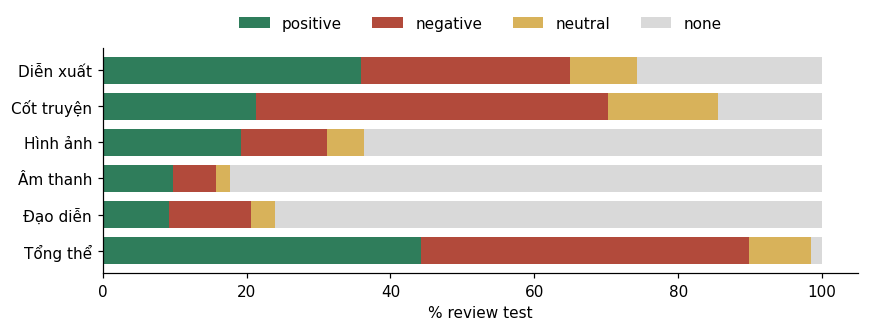

In [2]:
dist = pd.DataFrame(err["silver_distribution"]).T[LABELS]
dist_pct = dist.div(dist.sum(axis=1), axis=0) * 100
dist_pct.index = [VI[a] for a in dist_pct.index]
display(dist_pct.round(1))

ax = dist_pct.plot.barh(stacked=True, figsize=(8, 3.2), color=["#2f7d5b", "#b24a3b", "#d8b25a", "#d9d9d9"], width=0.75)
ax.invert_yaxis(); ax.set_xlabel("% review test"); ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.2), frameon=False)
plt.tight_layout(); plt.show()

**Nhận xét.** Âm thanh, đạo diễn, hình ảnh vắng mặt ở 64–82% review, nên lớp *none* chiếm ưu thế ở các khía cạnh này. Vì vậy khi huấn luyện nhóm dùng trọng số lớp
$w_c = \mathrm{clip}\big(\sqrt{N / (4 n_c)},\ 0{,}2,\ 5\big)$ cho từng khía cạnh, và độ đo chính là **Macro-F1** (trung bình đều các lớp) thay cho accuracy.

## 2. Nhãn silver từ LLM chạy cục bộ

IMDb không có nhãn theo khía cạnh, gán tay 50.000 review vượt quá sức nhóm. Nhóm cho **Qwen3-8B** (lượng tử 4 bit, chạy bằng llama.cpp trên GPU laptop 8 GB) gán nhãn cho cả 49.777 review, không dùng API trả phí.

Prompt cuối cùng (v3) là **evidence-first**: với mỗi khía cạnh, LLM phải chép nguyên văn một cụm từ trong review làm bằng chứng *trước*, rồi mới ra nhãn. Sau đó script kiểm tra: nhãn khác *none* mà bằng chứng không có trong review (khớp nguyên văn hoặc ít nhất 70% từ) sẽ bị ép về *none* (trừ overall).
Đầu ra bị ép theo JSON schema nên luôn đủ khoá và đúng nhãn.

Một dòng nhãn silver thật (nếu máy có thư mục `data/`):

In [3]:
silver_file = ROOT / "data/processed/imdb_absa_v1/silver_qwen3_8b_v3/test.jsonl"
if silver_file.exists():
    with open(silver_file, encoding="utf-8") as f:
        rec = json.loads(f.readline())
    display(pd.DataFrame({"nhãn": {a: rec["labels"][a] for a in ASPECTS},
                          "bằng chứng LLM trích ra": {a: rec["evidence"][a] for a in ASPECTS}}))
    print("review:", rec["review_id"], "| model:", rec["model"], "| prompt:", rec["prompt_version"], "|", rec["seconds"], "giây")
else:
    print("Không có data/ (thư mục này không đưa lên GitHub). Bỏ qua ví dụ.")

,nhãn,bằng chứng LLM trích ra
acting,neutral,Costner's character are realized early on
story,negative,no prior inkling or foreshadowing
visual,none,
sound,none,
direction,negative,dragged out a movie for far longer than necessary
overall,negative,it was all I could do to keep from turning it ...


review: test/neg/0_2 | model: Qwen3-8B-Q4_K_M.gguf | prompt: v3 | 3.88 giây


### Chất lượng nhãn: so với 300 review tham chiếu

Nhóm lấy ngẫu nhiên 300 review validation (150 khen, 150 chê) và gán nhãn tham chiếu theo đúng hướng dẫn. **Lưu ý trung thực:** bộ tham chiếu này do một LLM mạnh hơn (Claude) gán theo hướng dẫn, không phải nhãn người; kiểm tay bằng người đang được nhóm thực hiện trên 400 review test (mục 7).

In [4]:
rows = {}
for v, a in agree.items():
    per = a["comparison"]["per_aspect"]
    rows[f"prompt {v}"] = {VI[x]: per[x]["cohen_kappa"] for x in ASPECTS}
kappa = pd.DataFrame(rows).T
kappa["Trung bình"] = kappa.mean(axis=1)
display(kappa.round(2))

,Diễn xuất,Cốt truyện,Hình ảnh,Âm thanh,Đạo diễn,Tổng thể,Trung bình
prompt v2,0.43,0.57,0.57,0.39,0.48,0.77,0.54
prompt v3,0.67,0.60,0.70,0.78,0.78,0.77,0.72


Bắt LLM trích bằng chứng trước giúp κ trung bình 6 khía cạnh tăng từ **0,54 lên 0,72** (mức "khá tốt" theo thang Landis–Koch). Cải thiện lớn nhất ở âm thanh (+0,39) và đạo diễn (+0,30): prompt cũ hay gán nhãn cho khía cạnh mà review không thật sự nhắc tới, suy từ ấn tượng chung về bộ phim; bắt chép bằng chứng chặn được kiểu lỗi này.

## 3. Kết quả 3 mô hình

Cả ba mô hình đọc review đã cắt **128 token đầu + 382 token cuối** (tổng 512), rồi một lớp tuyến tính cho ra 6 × 4 logits (mỗi khía cạnh một softmax 4 lớp):

* **BERT đóng băng + BiLSTM**: mô hình của phần 1, encoder không học.
* **BERT-base fine-tune** (110M tham số).
* **RoBERTa-large fine-tune** (355M tham số, gradient checkpointing để vừa 8 GB).

Mỗi mô hình chạy 3 seed (42, 43, 44); chọn epoch theo Macro-F1 validation; tập test chỉ đánh giá một lần.

In [5]:
tab = {}
for k, r in results.items():
    agg = r["aggregate"]
    runs = r["runs"]
    rating = [x["overall_vs_imdb_rating"]["accuracy_on_decided"] for x in runs]
    ci = sig["systems"][k]["macro_f1_mean_ci95"]
    tab[NAMES[k]] = {
        "Macro-F1": f'{agg["macro_f1"]["mean"]*100:.2f} ± {agg["macro_f1"]["sample_std"]*100:.2f}',
        "KTC 95%": f"[{ci[0]*100:.2f}; {ci[1]*100:.2f}]",
        "Nhận ra khía cạnh F1": round(agg["detection_f1"]["mean"] * 100, 2),
        "Cảm xúc F1": round(agg["sentiment_macro_f1"]["mean"] * 100, 2),
        "Overall khớp số sao (%)": round(np.mean(rating) * 100, 1),
        "Phút / seed": round(np.mean([x["training_seconds"] for x in runs]) / 60),
    }
display(pd.DataFrame(tab).T)

,Macro-F1,KTC 95%,Nhận ra khía cạnh F1,Cảm xúc F1,Overall khớp số sao (%),Phút / seed
BERT đóng băng + BiLSTM,62.58 ± 0.36,[62.21; 62.94],87.71,62.26,94.6,24
BERT-base fine-tune,67.86 ± 0.11,[67.47; 68.24],90.82,67.09,95.2,15
RoBERTa-large fine-tune,74.19 ± 0.13,[73.81; 74.56],92.09,75.01,97.5,63


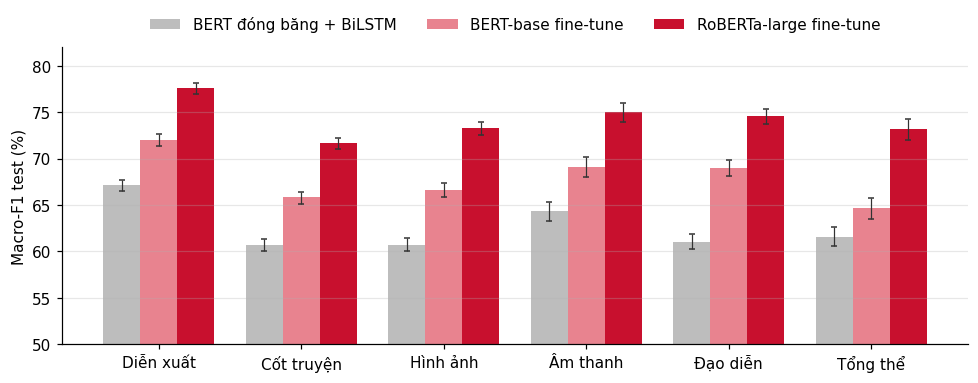

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(ASPECTS)); w = 0.26
for i, k in enumerate(["bilstm", "bert_base", "roberta_large"]):
    s = sig["systems"][k]
    v = np.array([s["per_aspect_macro_f1"][a] for a in ASPECTS]) * 100
    ci = np.array([s["per_aspect_ci95"][a] for a in ASPECTS]) * 100
    ax.bar(x + (i - 1) * w, v, w, color=COLORS[k], label=NAMES[k])
    ax.errorbar(x + (i - 1) * w, v, yerr=[v - ci[:, 0], ci[:, 1] - v], fmt="none", ecolor="#333", capsize=2, lw=0.8)
ax.set_xticks(x, [VI[a] for a in ASPECTS]); ax.set_ylim(50, 82); ax.set_ylabel("Macro-F1 test (%)")
ax.legend(ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.15)); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

**Nhận xét.** RoBERTa-large tốt nhất ở **mọi** khía cạnh, từ 71,6% (cốt truyện) đến 77,6% (diễn xuất). Độ lệch giữa các seed rất nhỏ (≤ 0,36 điểm), nên thứ hạng ổn định.
Cột cuối là kiểm tra **độc lập với LLM**: số sao do chính người viết cho. Khi mô hình kết luận overall là khen hoặc chê, kết luận đó khớp với số sao ở 97,5% review (RoBERTa-large).

## 4. Kiểm định thống kê

Review của cùng một bộ phim không độc lập với nhau, nên nhóm dùng **bootstrap ghép cặp lấy mẫu lại theo phim** (3.581 phim, 10.000 lần). Mỗi lần lấy mẫu, Macro-F1 được tính lại từ ma trận nhầm lẫn của các phim được chọn, trung bình qua 3 seed. Giá trị p hai phía được hiệu chỉnh **Holm** cho nhiều phép so sánh.

In [7]:
def cmp_table(items):
    return pd.DataFrame([{
        "So sánh": f'{NAMES[c["first"]]} vs {NAMES[c["second"]]}' + (f' ({VI[c["aspect"]]})' if "aspect" in c else ""),
        "Chênh lệch (điểm)": round(c["difference"] * 100, 2),
        "KTC 95%": f'[{c["ci95"][0]*100:.2f}; {c["ci95"][1]*100:.2f}]',
        "p (Holm)": round(c["p_value_holm"], 4),
    } for c in items])

display(cmp_table(sig["comparisons_mean"]))
per = sig["comparisons_per_aspect"]
print(f"So sánh theo từng khía cạnh: {sum(c['p_value_holm'] < 0.05 for c in per)}/{len(per)} có ý nghĩa ở mức 0,05;",
      f"p_holm lớn nhất = {max(c['p_value_holm'] for c in per):.4f}")

,So sánh,Chênh lệch (điểm),KTC 95%,p (Holm)
0,RoBERTa-large fine-tune vs BERT-base fine-tune,6.33,[5.99; 6.66],6.00e-04
1,RoBERTa-large fine-tune vs BERT đóng băng + Bi...,11.61,[11.24; 11.97],6.00e-04
2,BERT-base fine-tune vs BERT đóng băng + BiLSTM,5.28,[4.97; 5.59],6.00e-04


So sánh theo từng khía cạnh: 18/18 có ý nghĩa ở mức 0,05; p_holm lớn nhất = 0.0036


Cả 3 cặp đều có ý nghĩa (p_holm = 0,0006, đây là mức sàn của 10.000 lần lấy mẫu khi hiệu chỉnh cho 3 phép so sánh). Cả 18 so sánh theo từng khía cạnh cũng có ý nghĩa.

## 5. Phân tích lỗi

### 5.1. F1 từng lớp (RoBERTa-large, trung bình 3 seed)

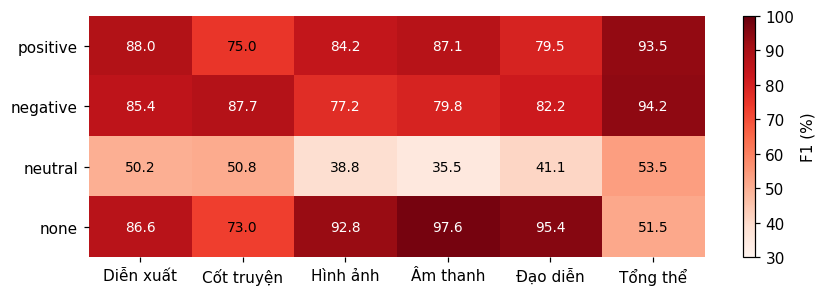

In [8]:
rob = err["systems"]["roberta_large"]["per_aspect"]
cf1 = pd.DataFrame({VI[a]: rob[a]["class_f1"] for a in ASPECTS}).loc[LABELS] * 100
fig, ax = plt.subplots(figsize=(8, 2.8))
im = ax.imshow(cf1.values, cmap="Reds", vmin=30, vmax=100, aspect="auto")
ax.set_xticks(range(len(cf1.columns)), cf1.columns); ax.set_yticks(range(len(LABELS)), LABELS)
for i in range(cf1.shape[0]):
    for j in range(cf1.shape[1]):
        v = cf1.values[i, j]; ax.text(j, i, f"{v:.1f}", ha="center", va="center", color="white" if v > 75 else "black", fontsize=9)
ax.spines[:].set_visible(False); plt.colorbar(im, ax=ax, label="F1 (%)"); plt.tight_layout(); plt.show()

**Neutral là lớp yếu nhất** (F1 khoảng 35–54%). Đây cũng là nơi mô hình lớn giúp nhiều nhất: RoBERTa-large hơn BERT-base 9–17 điểm ở lớp neutral.

### 5.2. Các kiểu nhầm phổ biến nhất

In [9]:
rows = []
for a in ASPECTS:
    for e in rob[a]["top_errors"][:3]:
        rows.append({"Khía cạnh": VI[a], "Silver": e["silver"], "Mô hình đoán": e["prediction"],
                     "Số review / seed": round(e["count_per_seed"]), "% lỗi của khía cạnh": round(e["share_of_errors"] * 100, 1)})
display(pd.DataFrame(rows))

,Khía cạnh,Silver,Mô hình đoán,Số review / seed,% lỗi của khía cạnh
0,Diễn xuất,neutral,positive,479,11.6
1,Diễn xuất,positive,neutral,473,11.4
2,Diễn xuất,negative,none,401,9.7
3,Cốt truyện,neutral,positive,924,16.2
4,Cốt truyện,negative,neutral,754,13.2
5,Cốt truyện,neutral,negative,737,12.9
6,Hình ảnh,none,negative,602,17.7
7,Hình ảnh,none,positive,509,15.0
8,Hình ảnh,none,neutral,327,9.6
9,Âm thanh,none,negative,250,17.3


Hai kiểu lỗi khác nhau theo khía cạnh:
* **Hình ảnh, âm thanh, đạo diễn**: phần lớn lỗi (66–73%) là chuyện *có nhắc tới hay không* (một phía là *none*).
* **Diễn xuất, cốt truyện, tổng thể**: phần lớn lỗi dính tới *neutral* (55%, 64%, 78%).
Nhầm hẳn khen thành chê (hoặc ngược lại) hiếm: 2–16% số lỗi.

### 5.3. Review dài và số sao IMDb

,≤ 512 token,> 512 token (bị cắt giữa),Chênh lệch
BERT đóng băng + BiLSTM,63.03,57.18,-5.85
BERT-base fine-tune,68.55,61.25,-7.30
RoBERTa-large fine-tune,75.13,66.75,-8.38


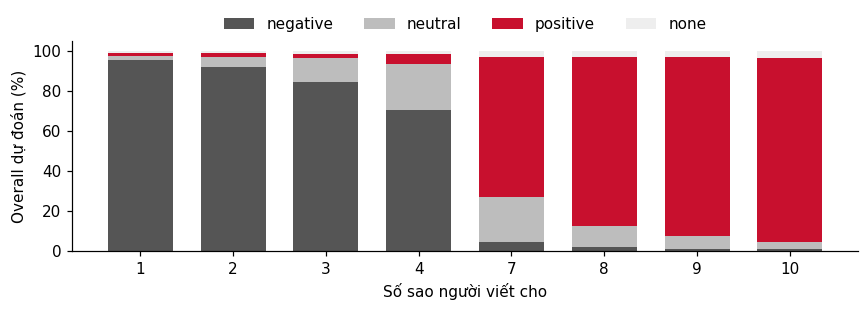

In [10]:
lg = pd.DataFrame({NAMES[k]: {g: err["systems"][k]["length_groups"][g]["macro_f1"] * 100 for g in ("short", "long")}
                   for k in ("bilstm", "bert_base", "roberta_large")}).T
lg.columns = ["≤ 512 token", "> 512 token (bị cắt giữa)"]
lg["Chênh lệch"] = lg.iloc[:, 1] - lg.iloc[:, 0]
display(lg.round(2))

by = err["roberta_overall_by_star_rating"]
stars = list(by)
fig, ax = plt.subplots(figsize=(8, 3))
bottom = np.zeros(len(stars))
for lab, c in (("negative", "#555"), ("neutral", "#bdbdbd"), ("positive", "#c8102e"), ("none", "#eee")):
    v = np.array([by[s][lab] for s in stars]) * 100
    ax.bar(stars, v, 0.7, bottom=bottom, color=c, label=lab); bottom += v
ax.set_xlabel("Số sao người viết cho"); ax.set_ylabel("Overall dự đoán (%)")
ax.legend(ncol=4, frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.18)); plt.tight_layout(); plt.show()

* Review dài hơn 512 token thấp hơn khoảng 8 điểm: nhận xét về nhạc hay hình ảnh thường nằm ở **đoạn giữa** bị bỏ. Với bài toán 2 lớp, cắt đầu–cuối gần như không mất gì; với ABSA thì có.
* LLM **không hề thấy số sao**, nhưng dự đoán *neutral* tập trung ở review 4 sao và 7 sao (khoảng 23%), đúng nơi người viết khen chê lẫn lộn. Đây là bằng chứng lớp neutral có nghĩa thật chứ không phải nhiễu.

### 5.4. Ca khó: cả 9 lượt chạy cùng khác nhãn silver

In [11]:
hc = pd.DataFrame({VI[a]: {"Cả 9 lượt sai": v["all_9_runs_wrong"], "Sai và cùng một nhãn": v["all_9_runs_wrong_and_agree"],
                           "% review": round(v["share_of_reviews"] * 100, 2)} for a, v in err["hard_cases"].items()}).T
display(hc)
ex = err["hard_cases"]["acting"]["examples"][0]
print(f'Ví dụ ({ex["review_id"]}, {ex["rating"]} sao): silver = {ex["silver"]}, cả 9 lượt đoán {ex["all_models_predict"]}')
print("Bằng chứng LLM:", ex["llm_evidence"])

,Cả 9 lượt sai,Sai và cùng một nhãn,% review
Diễn xuất,1782.0,1079.0,4.32
Cốt truyện,2589.0,1614.0,6.46
Hình ảnh,1403.0,826.0,3.30
Âm thanh,648.0,394.0,1.58
Đạo diễn,998.0,626.0,2.50
Tổng thể,1043.0,658.0,2.63


Ví dụ (test/neg/9954_4, 4 sao): silver = positive, cả 9 lượt đoán negative
Bằng chứng LLM: Zucco and Strange's presence, along with the cute Anne Nagel


Ví dụ trên là trường hợp **mô hình sai**: người viết nói nếu không có các diễn viên đó thì phim "không xem nổi", tức là khen diễn xuất trong một review chê; cả 9 lượt chạy đều bị giọng chê chung kéo về *negative*. Đọc thêm các ca khác thì có cả những ca **nhãn LLM sai**. Nhóm ca này là ứng viên ưu tiên cho kiểm tay.

## 6. Thử mô hình trên review mới

Ô dưới gọi demo server (`run\absa-demo.cmd`, http://127.0.0.1:8766). Server nạp RoBERTa-large (seed 43) và BERT-base (seed 42), là các seed có Macro-F1 validation cao nhất. Nếu server chưa chạy, ô sẽ chỉ in hướng dẫn.

In [12]:
import urllib.request

def absa(text, url="http://127.0.0.1:8766/api/predict"):
    req = urllib.request.Request(url, data=json.dumps({"text": text}).encode(), headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=120) as r:
        return json.loads(r.read())

review = ("The two leads are wonderful together, and the actress playing the older sister gives a quiet, "
          "heartbreaking performance. Unfortunately the script explains every twist twice and the last thirty "
          "minutes drag on forever. The cinematography is lovely. Worth seeing for the acting, but I left disappointed.")
try:
    out = absa(review)
    table = {m["name"]: {VI[a]: f'{out["results"][m["key"]]["aspects"][a]["label"]} '
                                f'({max(out["results"][m["key"]]["aspects"][a]["probabilities"].values())*100:.0f}%)'
                         for a in out["aspects"]} for m in out["models"]}
    display(pd.DataFrame(table))
    print(f'{out["results"]["roberta_large"]["token_count"]} token, {out["seconds"]:.2f} giây trên {out["device"]}')
except OSError:
    print("Demo server chưa chạy. Mở run\\absa-demo.cmd rồi chạy lại ô này.")

,RoBERTa-large,BERT-base
Diễn xuất,positive (96%),positive (91%)
Cốt truyện,negative (96%),negative (85%)
Hình ảnh,positive (99%),positive (94%)
Âm thanh,none (98%),none (96%)
Đạo diễn,none (99%),none (95%)
Tổng thể,negative (52%),negative (60%)


56 token, 0.20 giây trên cpu


## 7. Kết luận và giới hạn

* Một LLM 8B chạy trên laptop, khi bị buộc **trích bằng chứng trước**, gán được nhãn khía cạnh đủ tốt (κ = 0,72 so với bộ tham chiếu) cho cả 49.777 review trong khoảng 21 giờ, không tốn tiền API.
* Huấn luyện trên nhãn đó, **RoBERTa-large đạt Macro-F1 74,19%**, hơn BERT-base 6,33 điểm và hơn mô hình BiLSTM của phần 1 tới 11,61 điểm; mọi chênh lệch có ý nghĩa thống kê.
* Lỗi tập trung ở lớp **neutral** và ở việc **nhận ra khía cạnh có được nhắc tới** với hình ảnh, âm thanh, đạo diễn; review dài bị thiệt vì phần giữa bị cắt.

**Giới hạn.** Mọi điểm số đo so với nhãn silver của LLM, chưa phải nhãn người. Nhóm đang kiểm tay 400 review test (`reports/absa_v1/human_check/`, 3 người, 100 review chung để đo Fleiss κ); kết quả sẽ bổ sung vào bài báo.